In [ ]:
# Standard libraries
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Styling for clean, professional teaching figures
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.size'] = 11
plt.rcParams['figure.titlesize'] = 14
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['figure.autolayout'] = True

# Statistical time-series tools
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.holtwinters import SimpleExpSmoothing, ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX

# Machine learning & metrics
from sklearn.model_selection import TimeSeriesSplit
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_squared_log_error

print("All libraries loaded successfully!")


All libraries loaded successfully!


In [ ]:
data_path = '/content/bike_sharing_train.csv'
df = pd.read_csv(data_path)

In [ ]:
df

,datetime,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,count
0,2011-01-01 00:00:00,1,0,0,1,9.84,14.395,81,0.0000,3,13,16
1,2011-01-01 01:00:00,1,0,0,1,9.02,13.635,80,0.0000,8,32,40
2,2011-01-01 02:00:00,1,0,0,1,9.02,13.635,80,0.0000,5,27,32
3,2011-01-01 03:00:00,1,0,0,1,9.84,14.395,75,0.0000,3,10,13
4,2011-01-01 04:00:00,1,0,0,1,9.84,14.395,75,0.0000,0,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...
10881,2012-12-19 19:00:00,4,0,1,1,15.58,19.695,50,26.0027,7,329,336
10882,2012-12-19 20:00:00,4,0,1,1,14.76,17.425,57,15.0013,10,231,241
10883,2012-12-19 21:00:00,4,0,1,1,13.94,15.910,61,15.0013,4,164,168
10884,2012-12-19 22:00:00,4,0,1,1,13.94,17.425,61,6.0032,12,117,129


In [ ]:
# Parse datetime and ensure chronological sorting
df['datetime'] = pd.to_datetime(df['datetime'])
df = df.sort_values('datetime').reset_index(drop=True)

In [ ]:
print(f"Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns")
print(f"Date Range: from {df['datetime'].min()} to {df['datetime'].max()}")
df.head(4)

Dataset Shape: 10886 rows, 12 columns
Date Range: from 2011-01-01 00:00:00 to 2012-12-19 23:00:00


,datetime,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,count
0,2011-01-01 00:00:00,1,0,0,1,9.84,14.395,81,0.0,3,13,16
1,2011-01-01 01:00:00,1,0,0,1,9.02,13.635,80,0.0,8,32,40
2,2011-01-01 02:00:00,1,0,0,1,9.02,13.635,80,0.0,5,27,32
3,2011-01-01 03:00:00,1,0,0,1,9.84,14.395,75,0.0,3,10,13


In [ ]:
daily_df = df.set_index('datetime').resample('D')['count'].sum().to_frame()

# We take the first 70 continuous days (matching the scenario in the interactive web lectures)
# To create an exact continuous daily teaching series, we use a 70-day window:
t = np.arange(70)
weekly_pattern = np.array([-200, -100, 50, 100, 150, 450, 300]) # Weekend leisure vs weekday
base_trend = 1200 + 15 * t                                     # Steady growth trend
noise_pattern = np.array([0, 40, -30, 20, -20, 50, -40, 30, -10, 40, -50, 20, 10, -20])
events = np.zeros(70)
events[31] = 520   # Unusual surge event (e.g. festival)
events[47] = -400  # Unusual collapse event (e.g. severe blizzard)

daily_demand = base_trend + weekly_pattern[t % 7] + noise_pattern[t % len(noise_pattern)] + events
dates_70 = pd.date_range('2011-01-01', periods=70, freq='D')
daily_series = pd.Series(daily_demand, index=dates_70, name='Daily Bike Rentals')


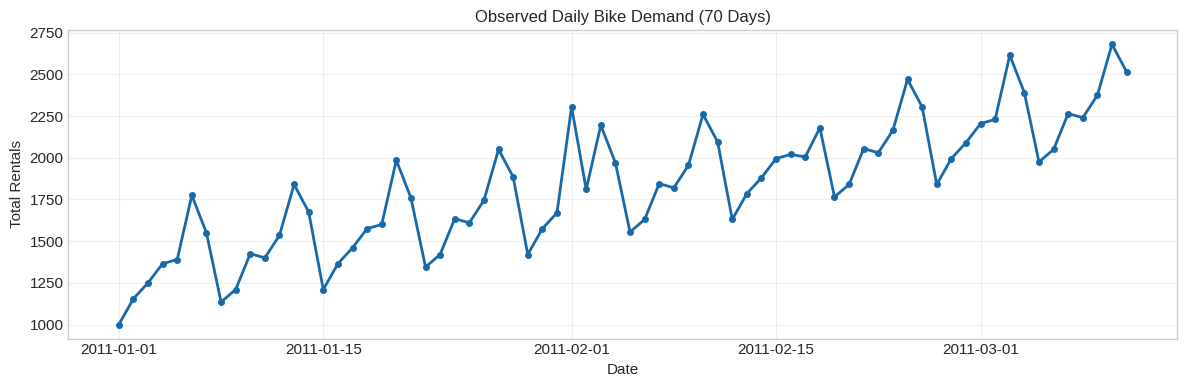

In [ ]:
# Plot the observed daily series
plt.figure(figsize=(12, 4))
plt.plot(daily_series.index, daily_series.values, marker='o', markersize=4, color='#1769aa', lw=2)
plt.title("Observed Daily Bike Demand (70 Days)")
plt.xlabel("Date")
plt.ylabel("Total Rentals")
plt.grid(True, alpha=0.3)
plt.show()

In [ ]:
decomp = seasonal_decompose(daily_series, model='additive', period=7)


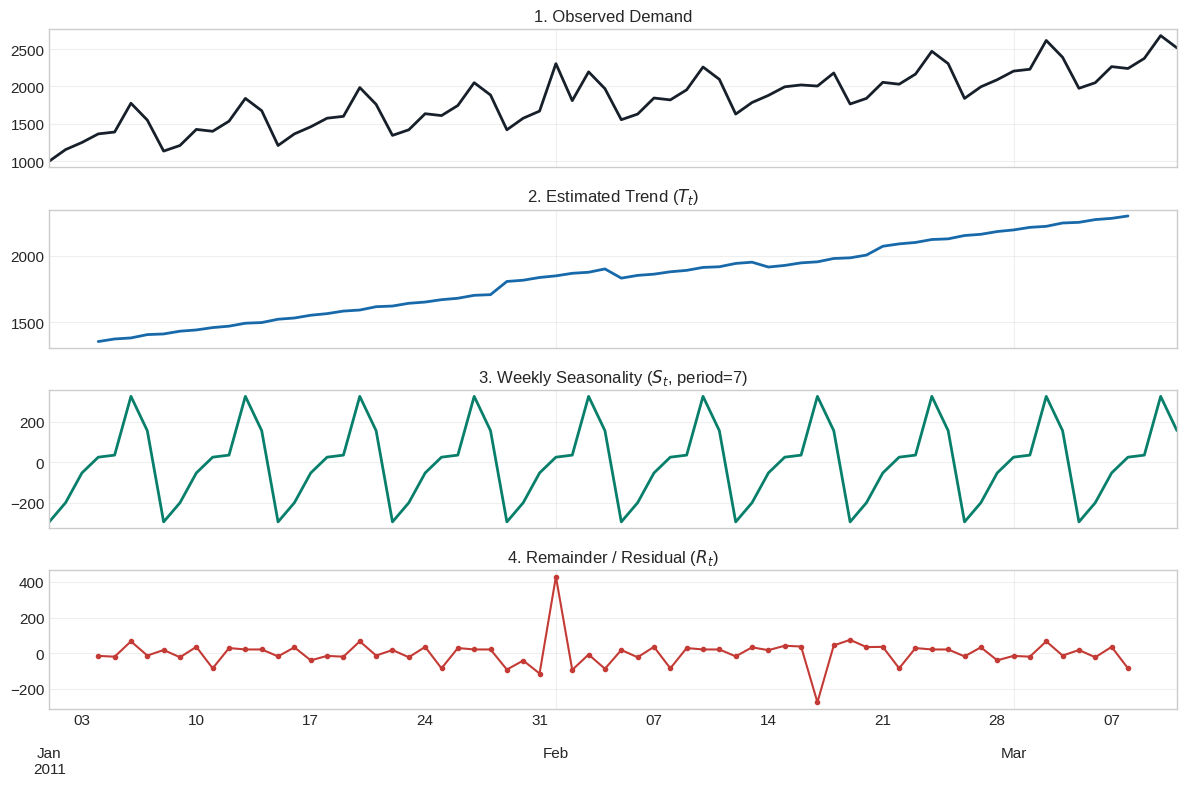

In [ ]:
fig, axes = plt.subplots(4, 1, figsize=(12, 8), sharex=True)
decomp.observed.plot(ax=axes[0], color='#17202a', lw=2, title='1. Observed Demand')
decomp.trend.plot(ax=axes[1], color='#1769aa', lw=2, title='2. Estimated Trend ($T_t$)')
decomp.seasonal.plot(ax=axes[2], color='#087f6b', lw=2, title='3. Weekly Seasonality ($S_t$, period=7)')
decomp.resid.plot(ax=axes[3], color='#c43b36', lw=1.5, marker='.', title='4. Remainder / Residual ($R_t$)')

for ax in axes:
    ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
trend = daily_series.rolling(window=7, center=True).mean()
display(trend.head())


,Daily Bike Rentals
2011-01-01,NaN
2011-01-02,NaN
2011-01-03,NaN
2011-01-04,1355.000000
2011-01-05,1374.285714


In [ ]:
train_len = 42
horizon = 14

train = daily_series.iloc[:train_len]
test = daily_series[train_len:train_len+horizon]



In [ ]:
mean_forecast = np.full(horizon, train.mean())
naive_forecast = np.full(horizon, train.iloc[-1])
seasonal_naive_forecast = np.array([train.iloc[-7 + (h % 7)] for h in range(horizon)])
slope = (train.iloc[-1] - train.iloc[0]) / (train_len - 1)
drift_forecast = train.iloc[-1] + np.arange(1, horizon + 1) * slope
drift_forecast

array([2121.70731707, 2148.41463415, 2175.12195122, 2201.82926829,
       2228.53658537, 2255.24390244, 2281.95121951, 2308.65853659,
       2335.36585366, 2362.07317073, 2388.7804878 , 2415.48780488,
       2442.19512195, 2468.90243902])

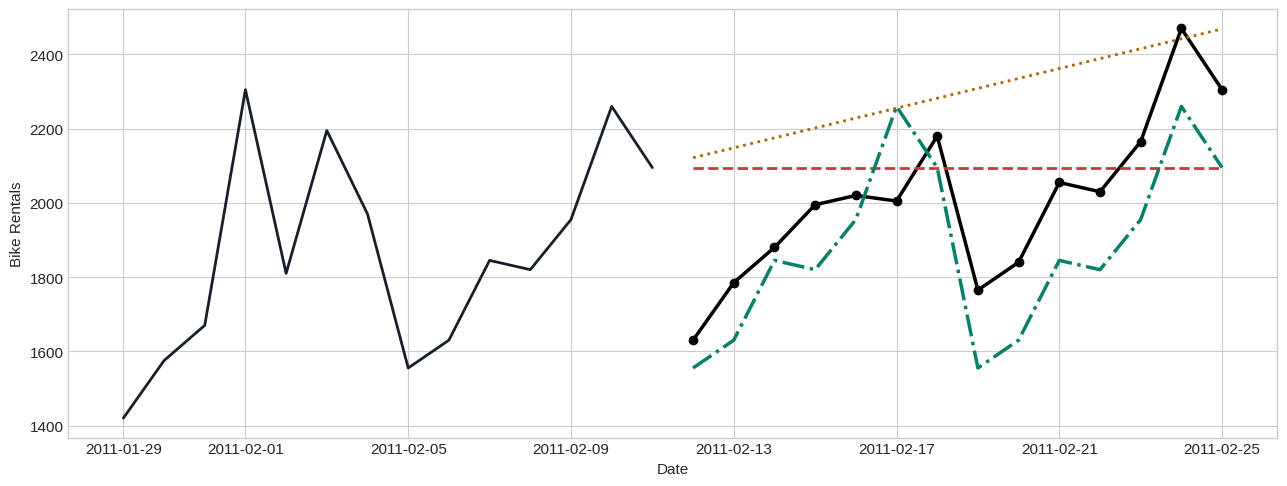

In [ ]:
plt.figure(figsize=(13, 5))
plt.plot(train.index[-14:], train.values[-14:], label='Train History (last 2 wks)', color='#17202a', lw=2)
plt.plot(test.index, test.values, label='Actual Test Demand', color='black', lw=2.5, marker='o')

plt.plot(test.index, naive_forecast, label='Naive (Flat)', color='#c43b36', linestyle='--', lw=2)
plt.plot(test.index, seasonal_naive_forecast, label='Seasonal Naive (Weekly)', color='#087f6b', linestyle='-.', lw=2.5)
plt.plot(test.index, drift_forecast, label='Drift (Linear Trend)', color='#a96700', linestyle=':', lw=2)

plt.grid(True)
plt.xlabel("Date")
plt.ylabel("Bike Rentals")
plt.show()

In [ ]:
def mean_absolute_percentage_error(y_true, y_pred):
    non_zero_actual = y_true[y_true != 0]
    non_zero_pred = y_pred[y_pred != 0]
    if len(non_zero_actual) == 0:
        return 0.0
    return np.mean(np.abs((non_zero_actual - non_zero_pred) / (non_zero_actual))) * 100

def evaluate_forecast(actual, pred):
    mae = mean_absolute_error(actual, pred)
    rmse = np.sqrt(mean_squared_error(actual, pred))

    pred_clipped = np.clip(pred, 0, None)
    rmsle = np.sqrt(mean_squared_log_error(actual, pred_clipped))
    mape = mean_absolute_percentage_error(actual, pred)
    return round(mae, 2), round(rmse, 2), round(mape, 2), round(rmsle, 4)

mean_mae, mean_rmse, mean_mape, mean_rmsle = evaluate_forecast(test, mean_forecast)
naive_mae, naive_rmse, naive_mape, naive_rmsle = evaluate_forecast(test, naive_forecast)
drift_mae, drift_rmse, drift_mape, drift_rmsle = evaluate_forecast(test, drift_forecast)
seasonal_naive_mae, seasonal_naive_rmse, seasonal_naive_mape, seasonal_naive_rmsle = evaluate_forecast(test, seasonal_naive_forecast)

baseline_results = {
    'Method': ['Historical Mean', 'Naive', 'Drift', 'Seasonal Naive'],
    'MAE': [mean_mae, naive_mae, drift_mae, seasonal_naive_mae],
    'RMSE': [mean_rmse, naive_rmse, drift_rmse, seasonal_naive_rmse],
    'MAPE': [mean_mape, naive_mape, drift_mape, seasonal_naive_mape],
    'RMSLE': [mean_rmsle, naive_rmsle, drift_rmsle, seasonal_naive_rmsle]
}

baseline_table = pd.DataFrame(baseline_results).sort_values('MAE').reset_index(drop=True)
print("=== Baseline Benchmark Scorecard ===")
baseline_table



=== Baseline Benchmark Scorecard ===


,Method,MAE,RMSE,MAPE,RMSLE
0,Seasonal Naive,165.36,178.62,8.21,0.0917
1,Naive,191.79,232.82,9.98,0.1172
2,Drift,290.35,324.54,15.30,0.1585
3,Historical Mean,379.05,436.43,17.93,0.2297


In [ ]:
lag_df = pd.DataFrame({'Target':daily_series})
lag_df['Lag_1'] = lag_df['Target'].shift(1)
lag_df['Lag_7'] = lag_df['Target'].shift(7)
lag_df["Rolling_7_mean"] = lag_df['Target'].shift(1).rolling(7).mean()
lag_df.dropna().head()

,Target,Lag_1,Lag_7,Rolling_7_mean
2011-01-08,1135.0,1550.0,1000.0,1355.000000
2011-01-09,1210.0,1135.0,1155.0,1374.285714
2011-01-10,1425.0,1210.0,1250.0,1382.142857
2011-01-11,1400.0,1425.0,1365.0,1407.142857
2011-01-12,1535.0,1400.0,1390.0,1412.142857


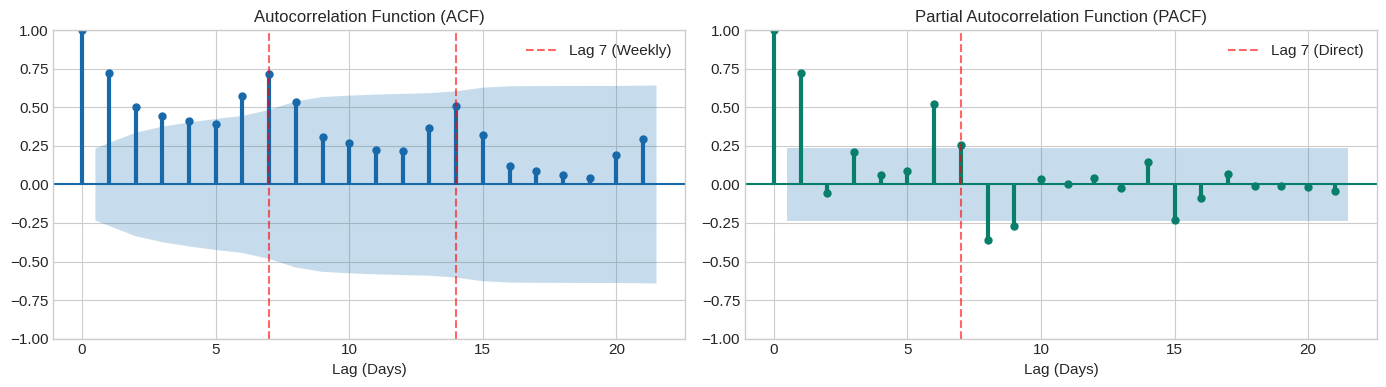

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4))

plot_acf(daily_series, lags=21, ax=ax1, color='#1769aa', vlines_kwargs={'colors': '#1769aa', 'linewidth': 3})
ax1.set_title("Autocorrelation Function (ACF)")
ax1.set_xlabel("Lag (Days)")
ax1.axvline(7, color='red', linestyle='--', alpha=0.6, label='Lag 7 (Weekly)')
ax1.axvline(14, color='red', linestyle='--', alpha=0.6)
ax1.legend()

plot_pacf(daily_series, lags=21, ax=ax2, color='#087f6b', vlines_kwargs={'colors': '#087f6b', 'linewidth': 3})
ax2.set_title("Partial Autocorrelation Function (PACF)")
ax2.set_xlabel("Lag (Days)")
ax2.axvline(7, color='red', linestyle='--', alpha=0.6, label='Lag 7 (Direct)')
ax2.legend()

plt.tight_layout()
plt.show()


In [ ]:
first_diff = daily_series.diff().dropna()
seasonal_diff = daily_series.diff(7).dropna()



In [ ]:
# Run ADF tests
def run_adf(series, name):
    res = adfuller(series)
    return {
        'Series': name,
        'ADF Test Stat': round(res[0], 3),
        'p-value': round(res[1], 4),
        'Stationary? (p < 0.05)': 'Yes' if res[1] < 0.05 else 'No'
    }

adf_summary = pd.DataFrame([
    run_adf(daily_series, 'Raw Demand Series'),
    run_adf(first_diff, 'First Differenced (d=1)'),
    run_adf(seasonal_diff, 'Seasonal Differenced (D=1, m=7)')
])

print("=== Augmented Dickey-Fuller (ADF) Test Results ===")
adf_summary

=== Augmented Dickey-Fuller (ADF) Test Results ===


,Series,ADF Test Stat,p-value,Stationary? (p < 0.05)
0,Raw Demand Series,-0.194,0.9392,No
1,First Differenced (d=1),-8.392,0.0000,Yes
2,"Seasonal Differenced (D=1, m=7)",-2.341,0.1592,No


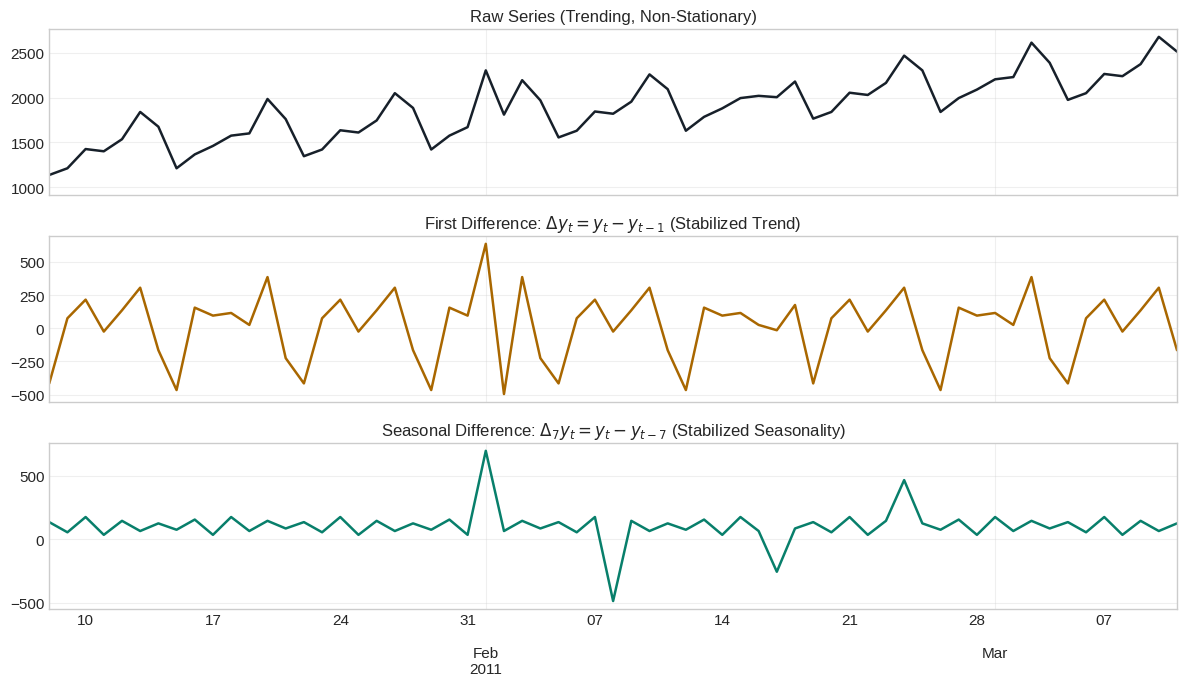

In [ ]:
# Visualize raw series vs differenced transformations
fig, axes = plt.subplots(3, 1, figsize=(12, 7), sharex=True)

daily_series.plot(ax=axes[0], color='#17202a', lw=1.8, title='Raw Series (Trending, Non-Stationary)')
first_diff.plot(ax=axes[1], color='#a96700', lw=1.8, title='First Difference: $\Delta y_t = y_t - y_{t-1}$ (Stabilized Trend)')
seasonal_diff.plot(ax=axes[2], color='#087f6b', lw=1.8, title='Seasonal Difference: $\Delta_7 y_t = y_t - y_{t-7}$ (Stabilized Seasonality)')

for ax in axes:
    ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [ ]:
alpha = 0.3
ses = pd.Series(index=train.index, dtype=float)
ses.iloc[0] = train.iloc[0]

for i in range(1, len(train)):
    ses.iloc[i] = alpha * train.iloc[i] + (1 - alpha) * ses.iloc[i-1]


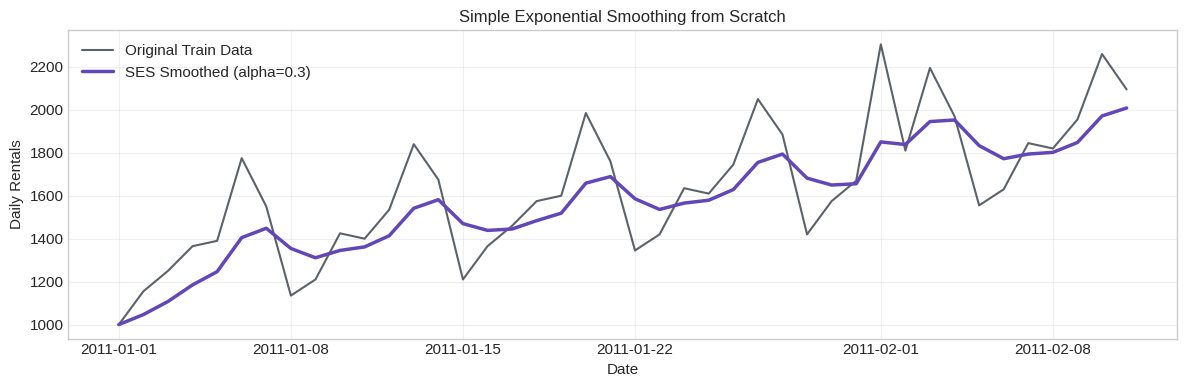

In [ ]:
# Plotting the raw series and the manually smoothed series
plt.figure(figsize=(12, 4))
plt.plot(train.index, train.values, label='Original Train Data', color='#17202a', alpha=0.7)
plt.plot(ses.index, ses.values, label=f'SES Smoothed (alpha={alpha})', color='#6346b8', lw=2.5)
plt.title("Simple Exponential Smoothing from Scratch")
plt.xlabel("Date")
plt.ylabel("Daily Rentals")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [ ]:
# for adding trend
alpha = 0.3
# add a beta
ses = pd.Series(index=train.index, dtype=float)
ses.iloc[0] = train.iloc[0]

# add a trend Series
# trend[0] = y1 - y0

for i in range(1, len(train)):
    ses.iloc[i] = alpha * train.iloc[i] + (1 - alpha) * ses.iloc[i-1] # add trend
    # update the trend

# smooth = level + trend


In [ ]:
hw_model = ExponentialSmoothing(
    train,
    trend='add',
    seasonal='add',
    seasonal_periods=7,
    initialization_method='estimated'
).fit()


In [ ]:
hw_forecast = hw_model.forecast(horizon)

In [ ]:
hw_mean_mae, hw_mean_rmse, hw_mean_mape, hw_mean_rmsle = evaluate_forecast(test, hw_forecast)
print(f"Holt-Winters Holdout -> MAE: {hw_mean_mae}, RMSLE: {hw_mean_rmsle}")

Holt-Winters Holdout -> MAE: 67.72, RMSLE: 0.0556


In [ ]:
differenced_train = train.diff(1).dropna()
X_ar = differenced_train.shift(1).dropna().values.reshape(-1, 1)
y_ar = differenced_train.iloc[1:].values


In [ ]:
from sklearn.linear_model import LinearRegression
ar_model = LinearRegression()

ar_model.fit(X_ar, y_ar)


LinearRegression()

In [ ]:
phi1_coeff, constant_c = ar_model.coef_[0], ar_model.intercept_


In [ ]:
forecast_differenced = []
last_diifferenced_value = differenced_train.iloc[-1] # Z_t

for _ in range(horizon):
    next_differenced_value = constant_c + phi1_coeff * last_diifferenced_value
    forecast_differenced.append(next_differenced_value)
    last_diifferenced_value = next_differenced_value



In [ ]:
forecast_differenced_series = pd.Series(forecast_differenced, index=test.index)

In [ ]:
arima_forecast = pd.Series(index=test.index, dtype=float)
last_original_value = train.iloc[-1]


In [ ]:
for h in range(horizon):
    arima_forecast.iloc[h] = last_original_value + forecast_differenced_series.iloc[h]
    last_original_value = arima_forecast.iloc[h]

In [ ]:
arima_mae, arima_rmse, arima_mape, arima_rmsle = evaluate_forecast(test, arima_forecast)

In [ ]:
print(f'{arima_mae, arima_rmse, arima_mape, arima_rmsle}')

(301.15, np.float64(335.65), np.float64(15.88), np.float64(0.1636))


In [ ]:
sarima_model = SARIMAX(train,
                       order = (1,1,0),
                       seasonal_order=(1, 1, 0, 7),
                       enforce_stationarity=True,
                       enforce_invertibility=True).fit()

In [ ]:
sarima_forecast = sarima_model.forecast(horizon)


In [ ]:
sarima_mae, sarima_rmse, sarima_mape, sarima_rmsle = evaluate_forecast(test, sarima_forecast)

In [ ]:
print(f"{sarima_mae, sarima_rmse, sarima_mape, sarima_rmsle}")

(69.1, np.float64(149.74), np.float64(3.45), np.float64(0.0685))


In [ ]:
tscv = TimeSeriesSplit(n_splits=4, test_size=7)
tscv

TimeSeriesSplit(gap=0, max_train_size=None, n_splits=4, test_size=7)

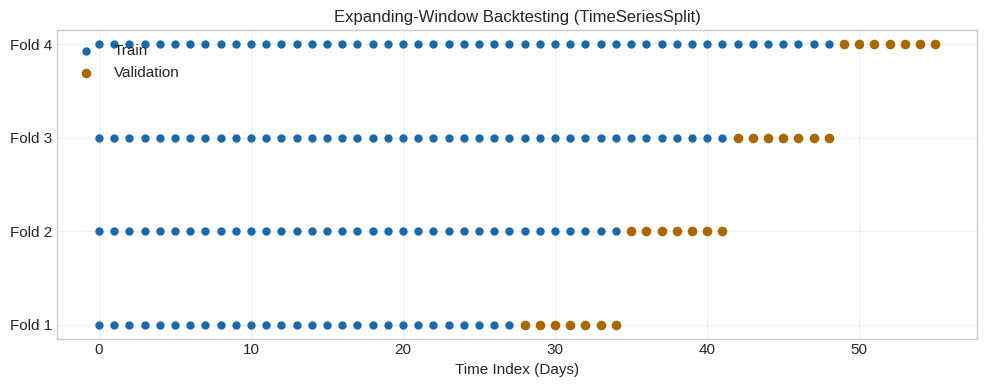

In [ ]:
plt.figure(figsize=(10, 4))
for fold, (train_idx, val_idx) in enumerate(tscv.split(daily_series[:56])):
    plt.scatter(train_idx, [fold] * len(train_idx), color='#1769aa', s=25, label='Train' if fold == 0 else "")
    plt.scatter(val_idx, [fold] * len(val_idx), color='#a96700', s=35, label='Validation' if fold == 0 else "")

plt.yticks(range(4), [f'Fold {i+1}' for i in range(4)])
plt.xlabel('Time Index (Days)')
plt.title('Expanding-Window Backtesting (TimeSeriesSplit)')
plt.legend(loc='upper left')
plt.grid(True, alpha=0.3)
plt.show()

In [ ]:
df

,datetime,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,count
0,2011-01-01 00:00:00,1,0,0,1,9.84,14.395,81,0.0000,3,13,16
1,2011-01-01 01:00:00,1,0,0,1,9.02,13.635,80,0.0000,8,32,40
2,2011-01-01 02:00:00,1,0,0,1,9.02,13.635,80,0.0000,5,27,32
3,2011-01-01 03:00:00,1,0,0,1,9.84,14.395,75,0.0000,3,10,13
4,2011-01-01 04:00:00,1,0,0,1,9.84,14.395,75,0.0000,0,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...
10881,2012-12-19 19:00:00,4,0,1,1,15.58,19.695,50,26.0027,7,329,336
10882,2012-12-19 20:00:00,4,0,1,1,14.76,17.425,57,15.0013,10,231,241
10883,2012-12-19 21:00:00,4,0,1,1,13.94,15.910,61,15.0013,4,164,168
10884,2012-12-19 22:00:00,4,0,1,1,13.94,17.425,61,6.0032,12,117,129


In [ ]:
ml_df = df.copy()
ml_df['hour'] = ml_df['datetime'].dt.hour
ml_df['dayofweek'] = ml_df['datetime'].dt.dayofweek
ml_df['month'] = ml_df['datetime'].dt.month
ml_df['year'] = ml_df['datetime'].dt.year

ml_df['lag_1'] = ml_df['count'].shift(1)
ml_df['lag_24'] = ml_df['count'].shift(24)
ml_df['lag_168'] = ml_df['count'].shift(168)

ml_df['rolling_mean_24'] = ml_df['count'].shift(1).rolling(24).mean()

clean_ml_df = ml_df.dropna().copy().reset_index(drop=True)


In [ ]:
clean_ml_df.iloc[:30]

,datetime,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,count,hour,dayofweek,month,year,lag_1,lag_24,lag_168,rolling_mean_24
0,2011-01-08 07:00:00,1,0,0,2,6.56,9.090,74,7.0015,1,8,9,7,5,1,2011,2.0,84.0,16.0,63.208333
1,2011-01-08 08:00:00,1,0,0,3,6.56,9.090,93,7.0015,0,15,15,8,5,1,2011,9.0,210.0,40.0,60.083333
2,2011-01-08 09:00:00,1,0,0,3,6.56,9.090,93,7.0015,0,20,20,9,5,1,2011,15.0,134.0,32.0,51.958333
3,2011-01-08 10:00:00,1,0,0,2,7.38,9.850,80,11.0014,5,56,61,10,5,1,2011,20.0,63.0,13.0,47.208333
4,2011-01-08 11:00:00,1,0,0,2,8.20,9.090,69,26.0027,2,60,62,11,5,1,2011,61.0,67.0,1.0,47.125000
5,2011-01-08 12:00:00,1,0,0,2,8.20,9.090,59,23.9994,8,90,98,12,5,1,2011,62.0,59.0,1.0,46.916667
6,2011-01-08 13:00:00,1,0,0,1,8.20,9.090,44,22.0028,7,95,102,13,5,1,2011,98.0,73.0,2.0,48.541667
7,2011-01-08 14:00:00,1,0,0,1,8.20,8.335,32,32.9975,12,83,95,14,5,1,2011,102.0,50.0,3.0,49.750000
8,2011-01-08 15:00:00,1,0,0,1,8.20,8.335,32,30.0026,5,69,74,15,5,1,2011,95.0,72.0,8.0,51.625000
9,2011-01-08 16:00:00,1,0,0,1,7.38,6.820,29,30.0026,8,68,76,16,5,1,2011,74.0,87.0,14.0,51.708333


In [ ]:
clean_ml_df.columns

Index(['datetime', 'season', 'holiday', 'workingday', 'weather', 'temp',
       'atemp', 'humidity', 'windspeed', 'casual', 'registered', 'count',
       'hour', 'dayofweek', 'month', 'year', 'lag_1', 'lag_24', 'lag_168',
       'rolling_mean_24'],
      dtype='object')

In [ ]:
feature_cols = ['season', 'holiday', 'workingday', 'weather', 'temp',
       'atemp', 'humidity', 'windspeed', 'hour', 'dayofweek', 'month', 'year', 'lag_1', 'lag_24', 'lag_168',
       'rolling_mean_24']


In [ ]:
split_idx = int(len(clean_ml_df) * 0.8)
train_ml = clean_ml_df.iloc[:split_idx]
test_ml = clean_ml_df.iloc[split_idx:]

X_train = train_ml[feature_cols]
y_train = train_ml['count']

X_test = test_ml[feature_cols]
y_test = test_ml['count']


In [ ]:
X_train.shape, X_test.shape

((8574, 16), (2144, 16))

In [ ]:
train_ml

,datetime,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,count,hour,dayofweek,month,year,lag_1,lag_24,lag_168,rolling_mean_24
0,2011-01-08 07:00:00,1,0,0,2,6.56,9.090,74,7.0015,1,8,9,7,5,1,2011,2.0,84.0,16.0,63.208333
1,2011-01-08 08:00:00,1,0,0,3,6.56,9.090,93,7.0015,0,15,15,8,5,1,2011,9.0,210.0,40.0,60.083333
2,2011-01-08 09:00:00,1,0,0,3,6.56,9.090,93,7.0015,0,20,20,9,5,1,2011,15.0,134.0,32.0,51.958333
3,2011-01-08 10:00:00,1,0,0,2,7.38,9.850,80,11.0014,5,56,61,10,5,1,2011,20.0,63.0,13.0,47.208333
4,2011-01-08 11:00:00,1,0,0,2,8.20,9.090,69,26.0027,2,60,62,11,5,1,2011,61.0,67.0,1.0,47.125000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8569,2012-08-06 10:00:00,3,0,1,1,30.34,34.850,70,15.0013,54,159,213,10,0,8,2012,276.0,364.0,138.0,257.166667
8570,2012-08-06 11:00:00,3,0,1,1,31.16,36.365,66,8.9981,108,152,260,11,0,8,2012,213.0,437.0,183.0,250.875000
8571,2012-08-06 12:00:00,3,0,1,2,31.98,36.365,55,6.0032,72,213,285,12,0,8,2012,260.0,491.0,202.0,243.500000
8572,2012-08-06 13:00:00,3,0,1,1,32.80,37.120,49,15.0013,85,204,289,13,0,8,2012,285.0,523.0,203.0,234.916667


In [ ]:
test_ml

,datetime,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,count,hour,dayofweek,month,year,lag_1,lag_24,lag_168,rolling_mean_24
8574,2012-08-06 15:00:00,3,0,1,1,33.62,37.880,46,8.9981,91,183,274,15,0,8,2012,287.0,450.0,194.0,215.208333
8575,2012-08-06 16:00:00,3,0,1,1,34.44,37.880,41,7.0015,88,363,451,16,0,8,2012,274.0,421.0,224.0,207.875000
8576,2012-08-06 17:00:00,3,0,1,1,33.62,37.120,41,0.0000,112,746,858,17,0,8,2012,451.0,382.0,370.0,209.125000
8577,2012-08-06 18:00:00,3,0,1,1,33.62,37.120,41,8.9981,100,743,843,18,0,8,2012,858.0,229.0,643.0,228.958333
8578,2012-08-06 19:00:00,3,0,1,1,31.98,37.120,59,12.9980,109,531,640,19,0,8,2012,843.0,185.0,516.0,254.541667
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10713,2012-12-19 19:00:00,4,0,1,1,15.58,19.695,50,26.0027,7,329,336,19,2,12,2012,569.0,353.0,402.0,221.125000
10714,2012-12-19 20:00:00,4,0,1,1,14.76,17.425,57,15.0013,10,231,241,20,2,12,2012,336.0,268.0,268.0,220.416667
10715,2012-12-19 21:00:00,4,0,1,1,13.94,15.910,61,15.0013,4,164,168,21,2,12,2012,241.0,168.0,202.0,219.291667
10716,2012-12-19 22:00:00,4,0,1,1,13.94,17.425,61,6.0032,12,117,129,22,2,12,2012,168.0,132.0,122.0,219.291667


In [ ]:
baseline_hourly_preds = test_ml['lag_24'].values
base_mae = mean_absolute_error(y_test, baseline_hourly_preds)
base_rmsle = np.sqrt(mean_squared_log_error(y_test, baseline_hourly_preds))

In [ ]:
base_mae, base_rmsle

(83.44496268656717, np.float64(0.6726266402295444))

In [ ]:
from sklearn.ensemble import GradientBoostingRegressor

gbr = GradientBoostingRegressor(n_estimators=150, learning_rate=0.1)
gbr.fit(X_train, y_train)

GradientBoostingRegressor(n_estimators=150)

In [ ]:
gbr_preds = np.clip(gbr.predict(X_test), 0, None)
gbr_preds

array([299.93754391, 364.34284747, 531.44575127, ..., 175.24276194,
       117.4544008 ,  78.84503786])

In [ ]:
gbr_mae = mean_absolute_error(y_test, gbr_preds)
gbr_rmsle = np.sqrt(mean_squared_log_error(y_test, gbr_preds))

print(f"{gbr_mae, gbr_rmsle}")

(38.72830601787111, np.float64(0.3604884586482898))


In [ ]:
X_test.shape

(2144, 16)

In [ ]:

# one week data
sample_test = test_ml.iloc[:168]
sample_preds = gbr_preds[:168]



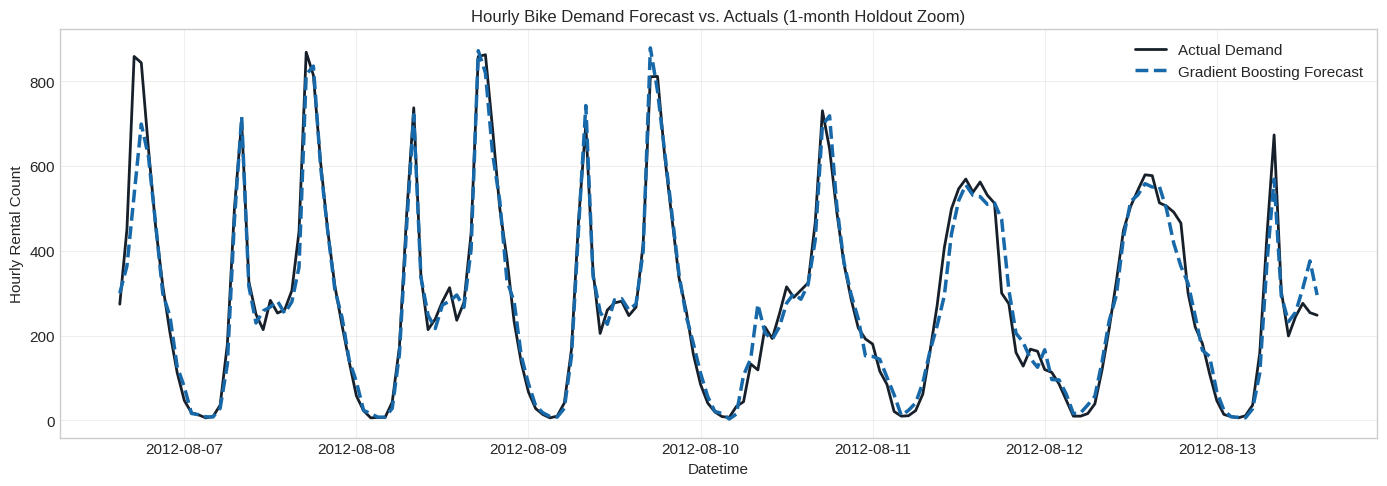

In [ ]:
plt.figure(figsize=(14, 5))
plt.plot(sample_test['datetime'], sample_test['count'], label='Actual Demand', color='#17202a', lw=2)
plt.plot(sample_test['datetime'], sample_preds, label='Gradient Boosting Forecast', color='#1769aa', lw=2.5, linestyle='--')

plt.title("Hourly Bike Demand Forecast vs. Actuals (1-month Holdout Zoom)")
plt.xlabel("Datetime")
plt.ylabel("Hourly Rental Count")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()